In [1]:
from qiskit import QuantumCircuit
from qiskit_aer import Aer
from qiskit.visualization import plot_histogram

from scipy.optimize import minimize

from sympy import sympify, symbols

import numpy as np
import matplotlib.pyplot as plt

from collections import Counter
import random

/var/folders/_t/q_d36zn17wv0qrfmtywnt18c0000gn/T/ipykernel_2308/138903912.py:1: DeprecationWarning: Using Qiskit with Python 3.9 is deprecated as of the 2.1.0 release. Support for running Qiskit with Python 3.9 will be removed in the 2.3.0 release, which coincides with when Python 3.9 goes end of life.
  from qiskit import QuantumCircuit


In [2]:
vObj=[]
vShots=[]
vCorrect=[]
GEN_SOL=[]

In [3]:
def b2s(x):
    if x == 0:
        return 1.0
    else:
        return -1.0

In [4]:
def obj_williamson_12(tv):

    s0=b2s(int(tv[0]))
    s1=b2s(int(tv[1]))
    s2=b2s(int(tv[2]))
    s3=b2s(int(tv[3]))
    s4=b2s(int(tv[4]))
    s5=b2s(int(tv[5]))
    s6=b2s(int(tv[6]))
    s7=b2s(int(tv[7]))

    obj = (
        s0*s1*s2*s3
        + s0*s1*s4*s5
        + s0*s1*s6*s7
        + 2*s0*s1
        + s2*s3*s4*s5
        + s2*s3*s6*s7
        + 2*s2*s3
        + s4*s5*s6*s7
        + 2*s4*s5
        + 2*s6*s7
        + 4
    )

    return obj

In [5]:
def hadamard_obj(vs):

    obj = obj_williamson_12(vs)

    F_Found = 0

    if abs(obj) < 1e-5:
        F_Found = 1
        GEN_SOL.append(vs)

    return obj, F_Found

In [6]:
def compute_expectation(counts):

    avg = 0
    sum_count = 0
    cnt_corr_sol = 0

    for bitstring, count in counts.items():

        obj, F_Found = hadamard_obj(bitstring)

        if F_Found > 0:
            cnt_corr_sol += count

        avg += obj * count
        sum_count += count

    vShots.append(sum_count)
    vCorrect.append(cnt_corr_sol)

    return avg / sum_count

In [7]:
def U_C_2body(qc, c, gamma, qbs):

    qc.cx(qbs[0], qbs[1])

    qc.rz(2*c*gamma, qbs[1])

    qc.cx(qbs[0], qbs[1])

In [8]:
def U_C_4body(qc, c, gamma, qbs):

    qc.cx(qbs[0], qbs[1])
    qc.cx(qbs[1], qbs[2])
    qc.cx(qbs[2], qbs[3])

    qc.rz(2*c*gamma, qbs[3])

    qc.cx(qbs[2], qbs[3])
    qc.cx(qbs[1], qbs[2])
    qc.cx(qbs[0], qbs[1])

In [9]:
def get_terms():

    return [
        (2,[0,1]),
        (2,[2,3]),
        (2,[4,5]),
        (2,[6,7]),
        (1,[0,1,2,3]),
        (1,[0,1,4,5]),
        (1,[0,1,6,7]),
        (1,[2,3,4,5]),
        (1,[2,3,6,7]),
        (1,[4,5,6,7])
    ]

In [10]:
def create_qaoa_circuit(nqubits, gamma, beta):

    qc = QuantumCircuit(nqubits)

    for i in range(nqubits):
        qc.h(i)

    for coeff, qubits in get_terms():

        if len(qubits) == 2:
            U_C_2body(qc, coeff, gamma, qubits)

        elif len(qubits) == 4:
            U_C_4body(qc, coeff, gamma, qubits)

    qc.barrier()

    for i in range(nqubits):
        qc.rx(2*beta, i)

    qc.measure_all()

    return qc

In [11]:
backend = Aer.get_backend('qasm_simulator')

In [12]:
vObj=[]


def expectation_from_theta(theta):

    gamma = theta[0]
    beta = theta[1]

    qc = create_qaoa_circuit(8, gamma, beta)

    counts = backend.run(
        qc,
        shots=512,
        seed_simulator=2
    ).result().get_counts()

    obj = compute_expectation(counts)

    vObj.append(obj)

    return obj



In [14]:
theta0 = [0.5, 0.5]

result = minimize(
    expectation_from_theta,
    theta0,
    # method='COBYLA',
    method = 'COBYLA'
    # method='Nelder-Mead',
    # method='Powell',
    # method='CG',
    # method='BFGS',
    # method='SLSQP',
    # options={
    #     'maxiter': 100,
    #     'disp': True
    # }
)

print(result)

 message: Optimization terminated successfully.
 success: True
  status: 1
     fun: 0.89453125
       x: [ 1.749e+00  1.744e+00]
    nfev: 34
   maxcv: 0.0


In [15]:
best_gamma = result.x[0]
best_beta = result.x[1]

qc_res = create_qaoa_circuit(8, best_gamma, best_beta)

counts = backend.run(
    qc_res,
    shots=512,
    seed_simulator=2
).result().get_counts()

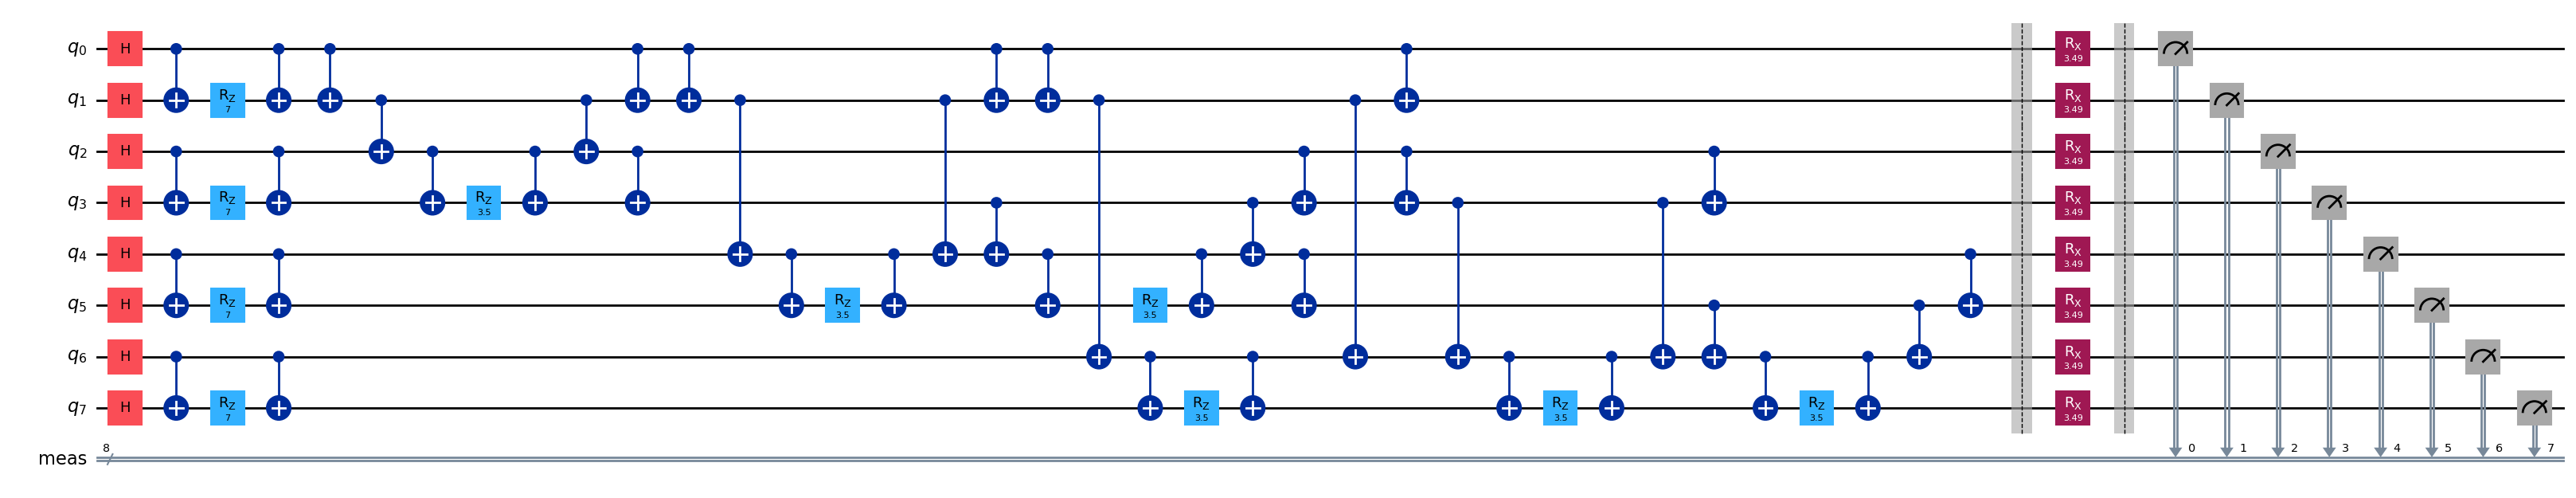

In [16]:
qc_res.draw(output='mpl', fold=-1)

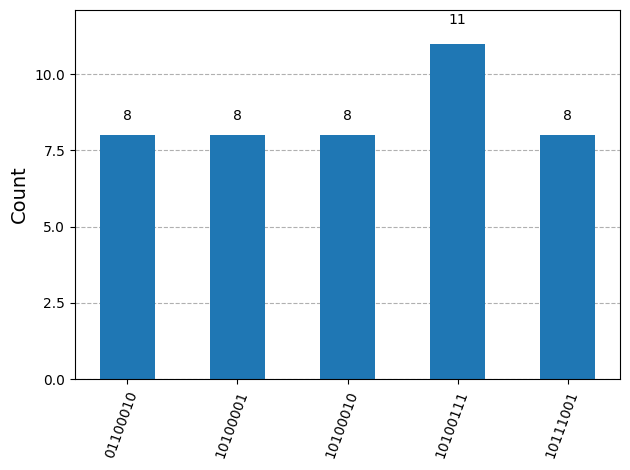

{'10100111': 11, '01100010': 8, '10100001': 8, '10100010': 8, '10111001': 8}


In [17]:
from qiskit.visualization import plot_histogram

top5 = dict(sorted(counts.items(),
                   key=lambda x: x[1],
                   reverse=True)[:5])

hist = plot_histogram(top5)

display(hist)
print(top5)

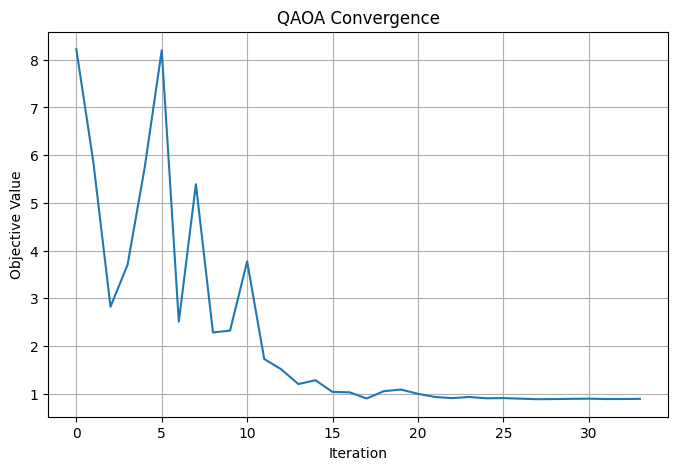

In [18]:
plt.figure(figsize=(8,5))
plt.plot(vObj)
plt.title('QAOA Convergence')
plt.xlabel('Iteration')
plt.ylabel('Objective Value')
plt.grid()
plt.show()

In [19]:
counter = Counter(counts)
most_common = counter.most_common()

best_sol = None
best_val = 1e9

for bitstring, freq in most_common:

    val = obj_williamson_12(bitstring)

    if val < best_val:
        best_val = val
        best_sol = bitstring

print('Best solution:', best_sol)
print('Minimum value:', best_val)

Best solution: 10100111
Minimum value: 0.0


In [20]:
def construct_ABCD(q):

    N=len(q)
    K05=int(N/4)

    tA = [ q[0:K05], q[(K05-1):0:-1] ]
    tB = [ q[K05:2*K05], q[(2*K05-1):K05:-1] ]
    tC = [ q[2*K05:3*K05], q[(3*K05-1):2*K05:-1] ]
    tD = [ q[3*K05:4*K05], q[(4*K05-1):3*K05:-1] ]

    qA=[]
    for item in tA:
        qA.extend(item)

    qB=[]
    for item in tB:
        qB.extend(item)

    qC=[]
    for item in tC:
        qC.extend(item)

    qD=[]
    for item in tD:
        qD.extend(item)

    NN=2*K05-1

    A=np.empty([NN,NN], dtype=object)
    B=np.empty([NN,NN], dtype=object)
    C=np.empty([NN,NN], dtype=object)
    D=np.empty([NN,NN], dtype=object)

    A[:,0]=qA
    B[:,0]=qB
    C[:,0]=qC
    D[:,0]=qD

    for m in range(1,NN):

        A[:,m] = np.roll(qA,m)
        B[:,m] = np.roll(qB,m)
        C[:,m] = np.roll(qC,m)
        D[:,m] = np.roll(qD,m)

    return(A,B,C,D)

In [21]:
def construct_symm_williamson(A,B,C,D):

    M,N=A.shape

    W=np.empty([4*M,4*N], dtype=object)

    W[0:M,0:M]=A
    W[0:M,M:2*M]=B
    W[0:M,2*M:3*M]=C
    W[0:M,3*M:4*M]=D

    W[M:2*M,0:M]=-B
    W[M:2*M,M:2*M]=A
    W[M:2*M,2*M:3*M]=-D
    W[M:2*M,3*M:4*M]=C

    W[2*M:3*M,0:M]=-C
    W[2*M:3*M,M:2*M]=D
    W[2*M:3*M,2*M:3*M]=A
    W[2*M:3*M,3*M:4*M]=-B

    W[3*M:4*M,0:M]=-D
    W[3*M:4*M,M:2*M]=-C
    W[3*M:4*M,2*M:3*M]=B
    W[3*M:4*M,3*M:4*M]=A

    return W

In [22]:
spin = [b2s(int(x)) for x in best_sol]

A,B,C,D = construct_ABCD(spin)

W = construct_symm_williamson(A,B,C,D)

DG = np.matmul(W, W.transpose())        # Multiply two matrices together

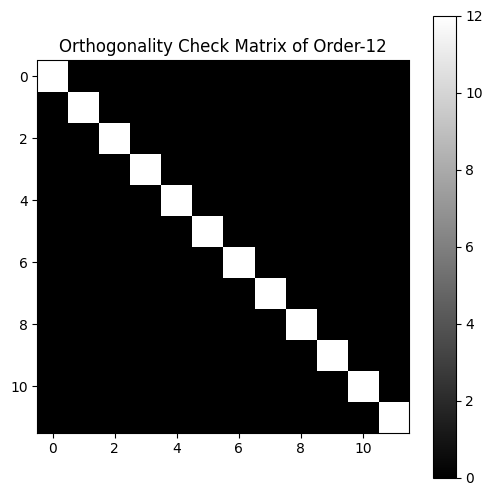

In [23]:
plt.figure(figsize=(6,6))
plt.imshow(DG.astype(float), cmap='gray')
plt.title('Orthogonality Check Matrix of Order-12')
plt.colorbar()
plt.show()

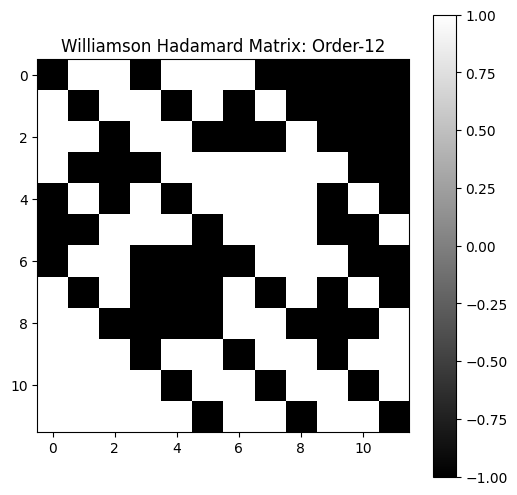

In [24]:
plt.figure(figsize=(6,6))
plt.imshow(W.astype(float), cmap='gray')
plt.title('Williamson Hadamard Matrix: Order-12')
plt.colorbar()
plt.show()

In [25]:
print('Final bitstring solution:', best_sol)
print('Final objective value:', best_val)

Final bitstring solution: 10100111
Final objective value: 0.0


In [26]:
print("\nOrthogonality Matrix:")
print(DG)


Orthogonality Matrix:
[[12.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0]
 [0.0 12.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0]
 [0.0 0.0 12.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0]
 [0.0 0.0 0.0 12.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0]
 [0.0 0.0 0.0 0.0 12.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0]
 [0.0 0.0 0.0 0.0 0.0 12.0 0.0 0.0 0.0 0.0 0.0 0.0]
 [0.0 0.0 0.0 0.0 0.0 0.0 12.0 0.0 0.0 0.0 0.0 0.0]
 [0.0 0.0 0.0 0.0 0.0 0.0 0.0 12.0 0.0 0.0 0.0 0.0]
 [0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 12.0 0.0 0.0 0.0]
 [0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 12.0 0.0 0.0]
 [0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 12.0 0.0]
 [0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 12.0]]
